# 02 - Whole-image model

This notebook trains a model that looks at each whole pill image and learns what a normal pill looks like. It will later be compared with the patch model.

## Steps

1. Load the shared split from `split.csv`. Use it only after notebook 01 has filled in the real image rows.
2. Resize each whole color image to 256 × 256. If the pixel values are rescaled, calculate that rescaling from the training images only.
3. Build a convolutional autoencoder that learns to rebuild a normal pill image.
4. Train on the normal training images only. Use the validation images to watch the reconstruction error, not to update the weights.
5. Check how well the model rebuilds the normal validation images.
6. Save the trained weights in `outputs/checkpoints/`.
7. Plot the training and validation error and save the figure in `outputs/figures/`.
8. Do not read test labels or defect masks. Notebook 04 will score this model in the same way as the patch model.


### 02 - Whole-Image Autoencoder

This notebook builds and trains a convolutional autoencoder to detect potential defects in pill images.

The model will learn what normal pills look like by training only on normal pill images. It will then reconstruct images and use reconstruction error to measure how different the output is from the original image.

The whole-image model will later be compared with the patch-based model.

### Objectives

1. Load the shared training and validation split.
2. Prepare and resize the pill images.
3. Build a convolutional autoencoder.
4. Train the model using normal pill images only.
5. Evaluate reconstruction performance on normal validation images.
6. Save the trained model and training results.


### 1. Import Libraries and Set Up Paths

Import the libraries needed for image processing, data preparation, model development, and visualization.

Set up the project paths for the dataset, shared split file, saved model checkpoints, and output figures.

In [39]:
# Import libraries
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms

# Find the project folder
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "split.csv").exists():
    PROJECT_DIR = PROJECT_DIR.parent

# Set folder locations
DATA_DIR = PROJECT_DIR / "data" / "pill"
SPLIT_FILE = PROJECT_DIR / "split.csv"

OUTPUT_DIR = PROJECT_DIR / "outputs"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"

# Create output folders
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Use Mac GPU if available
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Project folder:", PROJECT_DIR)
print("Dataset found:", DATA_DIR.exists())
print("Split file found:", SPLIT_FILE.exists())
print("Device:", device)

Project folder: /Users/morgancook/Documents/SYRACUSE UNIVERSITY/Fall 2026/IST 691/FinalProject_Pills/pill-defect-detection
Dataset found: True
Split file found: True
Device: mps


### 2. Load the Shared Data Split

Load the shared split.csv file created in notebook 01.

The 267 normal training images are divided into:
- 214 training images
- 53 validation images

Only normal pill images will be used in this notebook. The official test images and defect masks will not be used during training.

In [35]:
# Load the shared data split
split_df = pd.read_csv(SPLIT_FILE)

# Separate training and validation paths
train_paths = split_df[split_df["split"] == "train"]["relative_path"].tolist()
val_paths = split_df[split_df["split"] == "val"]["relative_path"].tolist()

# Check the number of images
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Training images: 214
Validation images: 53


### 3. Prepare the Images

Prepare the pill images for the autoencoder.

- Resize images to 256 × 256 pixels.
- Keep images in RGB color format.
- Convert images into PyTorch tensors.
- Scale pixel values to the range 0–1.

A custom PyTorch Dataset will be used to load the images.

In [36]:
# Resize images and convert them to tensors
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

# Load training images
train_images = []

for path in train_paths:
    image = Image.open(DATA_DIR / path).convert("RGB")
    train_images.append(transform(image))

# Load validation images
val_images = []

for path in val_paths:
    image = Image.open(DATA_DIR / path).convert("RGB")
    val_images.append(transform(image))

# Combine images into tensors
train_images = torch.stack(train_images)
val_images = torch.stack(val_images)

print("Training image shape:", train_images.shape)
print("Validation image shape:", val_images.shape)

Training image shape: torch.Size([214, 3, 256, 256])
Validation image shape: torch.Size([53, 3, 256, 256])


### 4. Create DataLoaders

Create training and validation DataLoaders to organize the images into batches.

The training DataLoader will shuffle the images, while the validation DataLoader will keep them in order.

A batch size of 16 will be used.

In [37]:
# Create DataLoaders
train_loader = DataLoader(train_images, batch_size=16, shuffle=True)
val_loader = DataLoader(val_images, batch_size=16, shuffle=False)

print("DataLoaders created successfully.")

DataLoaders created successfully.


### 5. Build the Convolutional Autoencoder

Build a convolutional autoencoder with two main components.

**Encoder:** Uses convolutional layers to compress the input image into a smaller representation.

**Decoder:** Uses transposed convolutional layers to reconstruct the original image from the compressed representation.

The model takes a 256 × 256 RGB image and attempts to recreate it.

In [40]:
class ConvAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder: compress the image
        self.encoder = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        # Decoder: reconstruct the image
        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):

        # Compress the image
        encoded = self.encoder(x)

        # Reconstruct the image
        reconstructed = self.decoder(encoded)

        return reconstructed

### 6. Initialize the Model

Initialize the convolutional autoencoder and select the available computing device.

Use Mean Squared Error (MSE) as the loss function to measure the difference between original and reconstructed images.

Use the Adam optimizer to update the model weights during training.

In [41]:
# Set random seeds for repeatable results
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Initialize the model
model = ConvAutoencoder().to(device)

# Set loss function
criterion = nn.MSELoss()

# Set optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Display model
print(model)

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): ReLU()
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Sigmoid()
  )
)


### 7. Train the Model

Train the autoencoder using only the normal training images.

During each epoch:
1. Pass training images through the autoencoder.
2. Compare reconstructed images with the original images.
3. Calculate the training loss.
4. Update the model weights.
5. Calculate validation loss without updating the model.

Save the model checkpoint whenever validation loss improves.

In [42]:
# Set number of training epochs
epochs = 50

# Store training results
train_losses = []
val_losses = []

# Track the best validation loss
best_val_loss = float("inf")

# Training loop
for epoch in range(epochs):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for images in train_loader:

        images = images.to(device)

        # Reconstruct images
        reconstructed = model(images)

        # Calculate loss
        loss = criterion(reconstructed, images)

        # Update model weights
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_images)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for images in val_loader:

            images = images.to(device)

            reconstructed = model(images)
            loss = criterion(reconstructed, images)

            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_images)

    # Save results
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    # Save model if validation loss improves
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss

        torch.save(
            model.state_dict(),
            CHECKPOINT_DIR / "whole_image_autoencoder.pth"
        )

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Training Loss: {epoch_train_loss:.6f} "
        f"Validation Loss: {epoch_val_loss:.6f}"
    )

Epoch [1/50] Training Loss: 0.091605 Validation Loss: 0.033207
Epoch [2/50] Training Loss: 0.025250 Validation Loss: 0.020771
Epoch [3/50] Training Loss: 0.015067 Validation Loss: 0.009667
Epoch [4/50] Training Loss: 0.006901 Validation Loss: 0.005209
Epoch [5/50] Training Loss: 0.004281 Validation Loss: 0.004028
Epoch [6/50] Training Loss: 0.003718 Validation Loss: 0.003816
Epoch [7/50] Training Loss: 0.003562 Validation Loss: 0.003732
Epoch [8/50] Training Loss: 0.003494 Validation Loss: 0.003669
Epoch [9/50] Training Loss: 0.003449 Validation Loss: 0.003645
Epoch [10/50] Training Loss: 0.003411 Validation Loss: 0.003604
Epoch [11/50] Training Loss: 0.003378 Validation Loss: 0.003580
Epoch [12/50] Training Loss: 0.003354 Validation Loss: 0.003542
Epoch [13/50] Training Loss: 0.003334 Validation Loss: 0.003515
Epoch [14/50] Training Loss: 0.003296 Validation Loss: 0.003480
Epoch [15/50] Training Loss: 0.003275 Validation Loss: 0.003475
Epoch [16/50] Training Loss: 0.003230 Validation 

### 8. Visualize Training Performance

Plot the training and validation loss across all epochs.

This visualization helps determine whether the model is learning to reconstruct normal pill images and whether the validation performance follows the training performance.

Save the resulting figure in the outputs/figures folder.

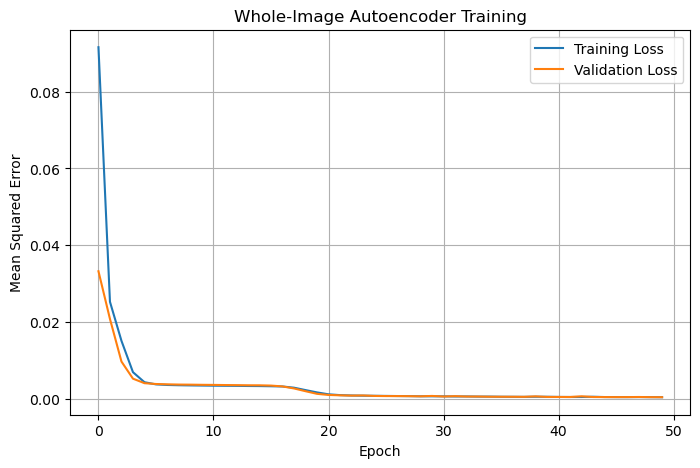

In [46]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Whole-Image Autoencoder Training")
plt.legend()
plt.grid(True)

# Save figure
plt.savefig(
    FIGURE_DIR / "whole_image_training_loss.png",
    bbox_inches="tight"
)

plt.show()

### 9. Load the Best Model

Load the model checkpoint with the lowest validation loss.

This ensures that the model used for reconstruction examples is the best-performing version saved during training.

In [47]:
# Load the best saved model
model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "whole_image_autoencoder.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded successfully.")
print("Best validation loss:", best_val_loss)

Best model loaded successfully.
Best validation loss: 0.0003702585367960328


### 10. Original vs. Reconstructed Images

Compare original normal validation images with their reconstructed versions.

This provides a visual example of how well the autoencoder has learned to recreate normal pill images.

The reconstruction results will be used as an initial check of model performance.

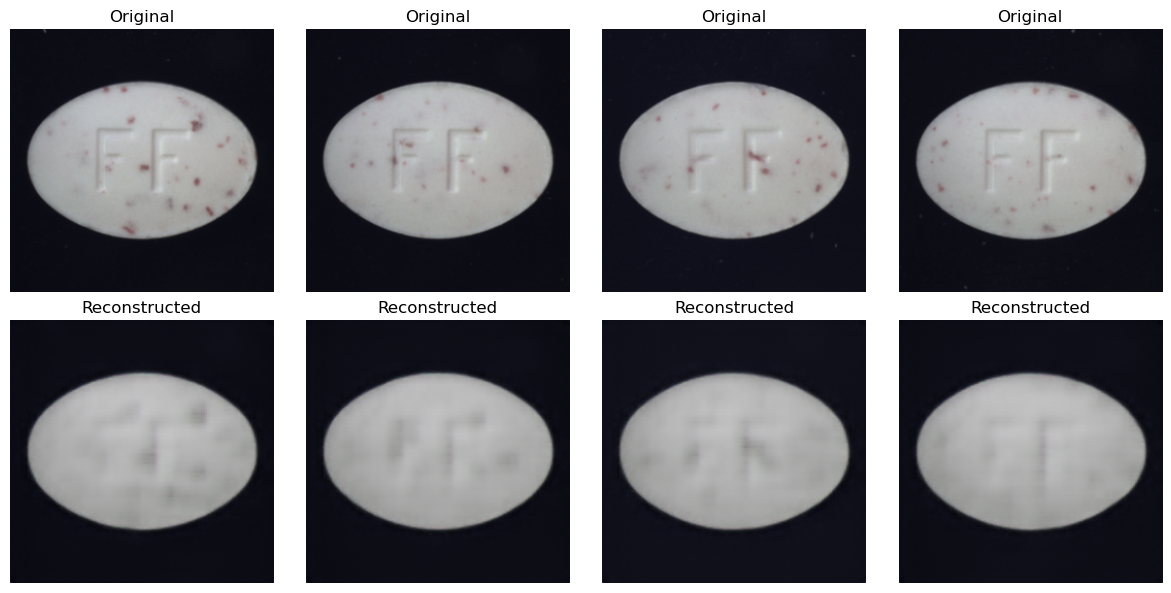

In [48]:
# Get a batch of validation images
images = next(iter(val_loader)).to(device)

# Reconstruct images
with torch.no_grad():
    reconstructed = model(images)

# Display original and reconstructed images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):

    original = images[i].cpu().permute(1, 2, 0)
    rebuilt = reconstructed[i].cpu().permute(1, 2, 0)

    axes[0, i].imshow(original)
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(rebuilt)
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "whole_image_reconstructions.png")
plt.show()

### 11. Summary

This notebook developed an initial whole-image convolutional autoencoder trained exclusively on normal pill images.

The model used 214 normal training images and 53 normal validation images.

Images were resized to 256 × 256 pixels and used to train the autoencoder to reconstruct normal pill appearances.

Training and validation loss were recorded and visualized. Original validation images were also compared with their reconstructed versions.

The trained model checkpoint and training figure were saved for use in the later evaluation and comparison stages.